# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Izar 2020's malignant manifold is **non-branching**: the gastrulation / somitogenesis /
neural-crest signatures form a single monotone gradient (Gast & pSom co-vary; Crest is the
opposite, terminal end) rather than a hub radiating to discrete subtypes. The correct
topology is a **principal curve** (ElPiGraph, non-branching by construction) fit on the
*joint* platform-integrated embedding — **not** a re-embedding (re-embedding an anisotropic
compartment fabricates folds).

**Scope decision (derived, not inherited).** Kürten 2021 confined its developmental axis to a
low-cycling lobe and excluded the cycling lobe. That is **not** transferable here: (i) the two
lobes carry *near-identical* developmental signature means, (ii) the developmental signatures
co-vary as one axis, and (iii) the low-cycling Leiden lobe is **not seed-stable** (Harmony
KMeans). The proliferation split is therefore **orthogonal** to the developmental axis, so the
whole manifold is the honest developmental object (Bischoff/Sun 2021 / Lee 2020 no-scoping
precedent). Reported caveat: pseudotime co-varies weakly with cycling (Spearman ρ≈+0.4), more
weakly than with the developmental signatures. The curve is rooted at the
gastrulation/somitogenesis-high tip and pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The
three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against
the shared **union** control pool and graph-smoothed to read geography rather than per-cell
dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].nunique()} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 1904 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.28
Gast: 56/81 genes present
pSom: 61/98 genes present
Crest: 76/104 genes present


### Scope decision — whole manifold vs low-cycling lobe (data-driven)
Test whether the developmental axis is confined to the low-cycling lobe (Kürten case, scoping
justified) or spans both lobes (Bischoff/Sun/Lee case, keep whole). Three facts settle it here:
(i) the smoothed signatures co-vary as one axis (Gast↔pSom positive, both opposite Crest);
(ii) the lobes have near-identical developmental means; (iii) the neural-crest-high terminus
sits overwhelmingly *inside* the low-cycling (Embryonic) lobe **and** the developmental axis
is present across both — so the split is orthogonal to the axis, not aligned with it.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across compartments:', frac)
print('-> developmental axis co-varies as one gradient with near-identical per-lobe means;')
print('   proliferation split is orthogonal to it -> keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.53
  Crest_sm vs Gast_sm: r = -0.68
  Crest_sm vs pSom_sm: r = -0.92

per-lobe smoothed developmental means (compartment):
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Cycling/Metabolic  -0.1270   0.2844    0.0056
Embryonic          -0.1635   0.2329    0.0560

Crest-high decile distributed across compartments: {'Embryonic': 1.0, 'Cycling/Metabolic': 0.0}
-> developmental axis co-varies as one gradient with near-identical per-lobe means;
   proliferation split is orthogonal to it -> keep whole manifold (no scoping).


### Cross-platform concordance — do both leaves reproduce the same axis?
The concat is only honest if the SmartSeq2 and 10x leaves *independently* carry the same
embryonic-signature relationships (rather than the axis being an integration artifact of one
platform). We compute the smoothed-geography correlations **within each platform separately**;
both must show Gast↔pSom positive and Crest opposed to both. This is the check nb01 refers to.

In [5]:
# Use RAW per-cell scores (not the joint-graph-smoothed ones) so the within-platform
# correlations are independent of cross-platform graph averaging.
print('per-platform RAW-score correlations (independent reproduction):')
print(f"{'platform':<12}{'n':>6}{'Gast~pSom':>12}{'Crest~Gast':>12}{'Crest~pSom':>12}")
for plat, d in adata.obs.groupby('platform', observed=True):
    gp = np.corrcoef(d['Gast'], d['pSom'])[0,1]
    cg = np.corrcoef(d['Crest'], d['Gast'])[0,1]
    cp = np.corrcoef(d['Crest'], d['pSom'])[0,1]
    print(f"{plat:<12}{len(d):>6}{gp:>+12.2f}{cg:>+12.2f}{cp:>+12.2f}")
print('-> both platforms independently show Gast~pSom positive and Crest opposed to both:')
print('   the developmental axis is reproduced per-platform, so concatenation is honest.')

per-platform RAW-score correlations (independent reproduction):
platform         n   Gast~pSom  Crest~Gast  Crest~pSom
10X            746       +0.10       -0.50       -0.56
SmartSeq2     1158       +0.14       -0.61       -0.59
-> both platforms independently show Gast~pSom positive and Crest opposed to both:
   the developmental axis is reproduced per-platform, so concatenation is honest.


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio
> 1 (minimum distance between graph-non-adjacent nodes, in units of median edge length)
certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth rather than a sharp V. Nodes chosen by a stability
sweep (topology invariant 15–30).

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for nn in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(sub)
    print(f'Nodes={nn}: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve (Nodes=20): {tips} tips, {forks} forks | fold ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

Nodes=15: 2 tips, 0 forks | fold self-approach ratio = 2.95
Nodes=20: 2 tips, 0 forks | fold self-approach ratio = 2.68
Nodes=30: 2 tips, 0 forks | fold self-approach ratio = 2.22
committed curve (Nodes=20): 2 tips, 0 forks | fold ratio = 2.68 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin. Pseudotime then flows to the neural-crest terminus.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.1254 pSom=+0.2863 Crest=+0.0030
tip 2: Gast=-0.1937 pSom=+0.2338 Crest=+0.0631
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.709 p=2.7e-290
  pSom_sm: rho=-0.584 p=8.4e-175
  Crest_sm: rho=+0.634 p=2.0e-214
  cyc_score: rho=+0.394 p=9.6e-72


### Render the fitted curve on the embedding (fold check)
Draw the curve edges over the cloud coloured by pseudotime, root starred — the visual
confirmation that the committed backbone does not fold back through the cells.

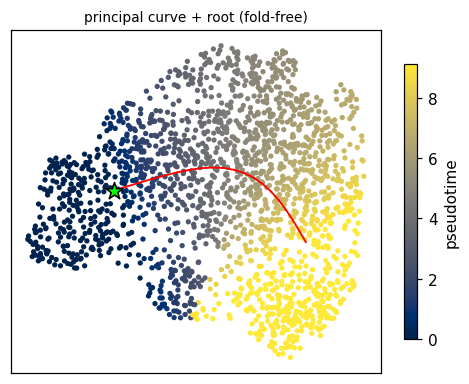

In [8]:
F = sub.uns['graph']['F'].T
fig, ax = plt.subplots(figsize=(4.5,3.6))
sca = ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], s=6, c=t, cmap='cividis')
for i,j in zip(*np.where(np.triu(B>0))): ax.plot(F[[i,j],0], F[[i,j],1], 'r-', lw=1.2)
ax.scatter(F[root,0], F[root,1], c='lime', s=140, marker='*', zorder=5, edgecolor='k')
ax.set_title('principal curve + root (fold-free)', size=9); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(sca, ax=ax, label='pseudotime', shrink=.8); fig.tight_layout()

### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD basis can
silently reflect an axis). The assertion confirms low pseudotime lands on the left.

In [9]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (low pt on the left)')

orientation: corr(x_lin, pseudotime) = +0.92 (low pt on the left)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


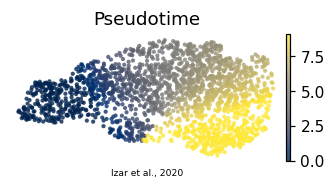

In [10]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Izar et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')